# IIC2115 - Resumen: Almacenamiento y Consulta de Datos

## Capítulo 4 - Sesión 02/11

Este notebook cubre los conceptos y herramientas que necesitan para resolver los ejercicios formativos E1 y E2.


## 1. El flujo completo: de un archivo a una base de datos consultable

El trabajo de esta sesión sigue un flujo lineal de 5 pasos:

1. **Leer el archivo** (CSV, JSON, etc.) → entender qué datos hay.
2. **Identificar entidades** → separar la "tabla gigante" en entidades lógicas.
3. **Crear las tablas en SQLite** → con llaves primarias, foráneas y restricciones.
4. **Cargar los datos** → recorrer el archivo e insertar filas en cada tabla.
5. **Consultar con SQL** → extraer información cruzada.

[Introducción a SQL W3 Schools](https://www.w3schools.com/sql/sql_intro.asp)

### ¿Por qué no quedarse con el CSV?

Un CSV es una sola tabla plana. Si tienes 1000 ventas del fabricante "Toyota", la palabra "Toyota" aparece 1000 veces. En una base de datos relacional, "Toyota" aparece una sola vez en la tabla de fabricantes, y cada venta apunta a ella con un número (la llave foránea). Esto evita inconsistencias y ahorra espacio.

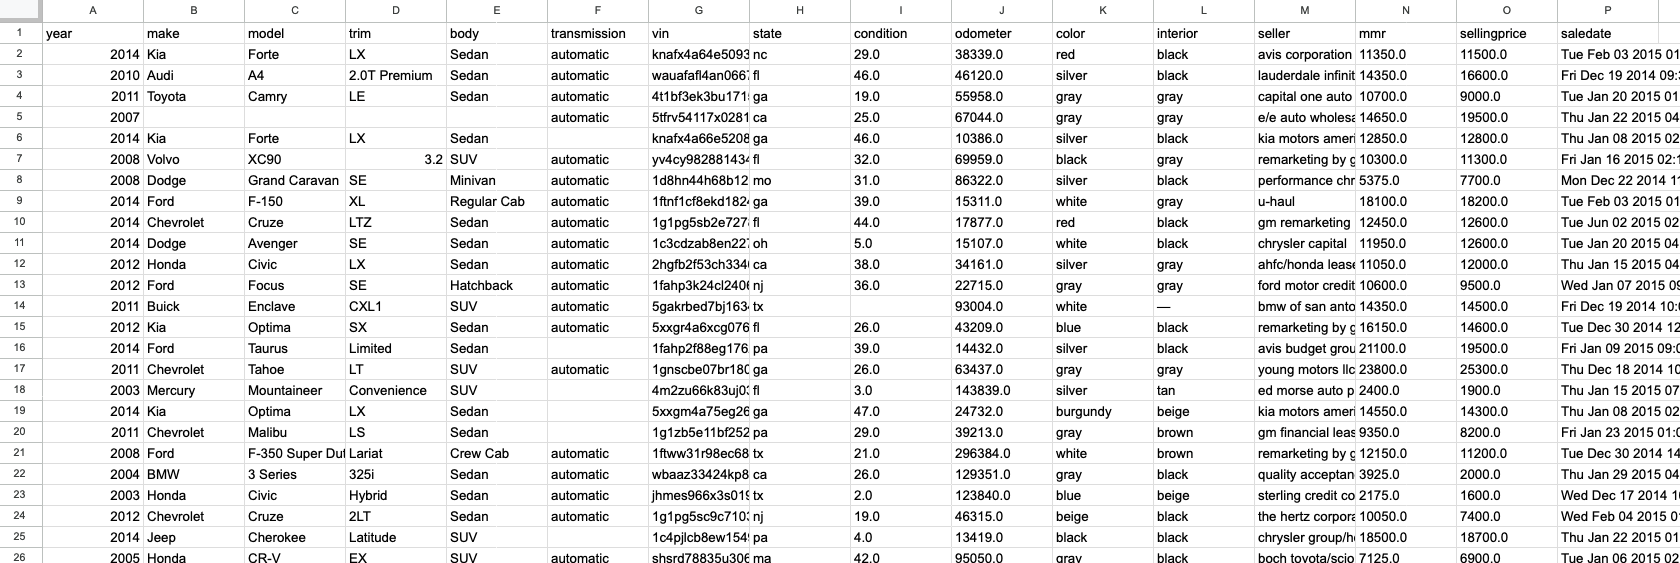


## 2. SQL: el lenguaje para trabajar con bases de datos

### Tabla, fila, columna

- Una **tabla** es una entidad (Películas, Actores, Géneros).
- Cada **fila** es un registro (una película específica).
- Cada **columna** es un atributo (título, año).
  -  Cada columna tiene un solo tipo de dato:
     - INTEGER: números enteros
     - REAL: números con decimales (punto flotante)
     - TEXT: texto/strings
     - BLOB: datos binarios (imágenes, archivos)
     - NULL: valor vacío.

SQL (*Structured Query Language*) es el lenguaje estándar para comunicarse con bases de datos relacionales. No es un lenguaje de programación general como Python, es un lenguaje declarativo: le dices **qué** quieres, no **cómo** hacerlo.

### ¿Qué es SQLite y por qué lo usamos?

Existen muchos motores de bases de datos relacionales. Los más conocidos son:

| Motor | Características | Usado en |
| --- | --- | --- |
| **PostgreSQL** | Robusto, open source, muchos tipos de datos | Startups, apps web, investigación |
| **MySQL / MariaDB** | Popular, rápido para lectura | WordPress, apps web masivas |
| **Oracle** | Comercial, empresarial | Bancos, grandes corporaciones |
| **SQL Server** | De Microsoft, integrado con .NET | Empresas con ecosistema Microsoft |
| **SQLite** | Sin servidor, un solo archivo, viene con Python | Apps móviles, prototipos, educación |

**SQLite** es distinto a todos los demás: no necesita instalar ni configurar un servidor. La base de datos completa vive en un solo archivo `.db` que puedes copiar, mover o borrar como cualquier otro archivo. Python lo trae incluido con la librería `sqlite3`.

¿Por qué lo usamos en el curso?
- No requiere instalación: funciona en Colab, en cualquier computador con Python.
- Es simple: el foco está en aprender SQL, no en configurar servidores.
- Es real: SQLite se usa en producción en Android, iOS, navegadores web y muchas aplicaciones.

Otra ventaja: **el SQL que aprenden acá es prácticamente el mismo** en todos los motores. Las diferencias son menores (tipos de datos, funciones específicas), pero la lógica de `SELECT`, `JOIN`, `GROUP BY`, etc. es universal.

Aprender más SQLite [aquí](https://www.w3schools.com/python/ref_module_sqlite3.asp)

### Dos partes de SQL

SQL se divide en dos sublenguajes:

**DDL (Data Definition Language)** — define la estructura de la base de datos:
- `CREATE TABLE`: crear una tabla con sus columnas, tipos y restricciones.
- `DROP TABLE`: eliminar una tabla.
- `ALTER TABLE`: modificar la estructura de una tabla existente.

**DML (Data Manipulation Language)** — trabaja con los datos dentro de las tablas:
- `INSERT INTO`: agregar filas a una tabla.
- `UPDATE`: modificar datos existentes.
- `DELETE`: eliminar filas.
- `SELECT`: consultar datos (la operación más usada).

### Tipos de datos en SQLite

SQLite es minimalista. Tiene solo 5 tipos de datos:

| Tipo | Qué guarda | Ejemplo en los ejercicios |
| --- | --- | --- |
| `INTEGER` | Números enteros | IDs, year, odometer, precios |
| `REAL` | Números con decimales | condition (2.5, 4.0) |
| `TEXT` | Texto/strings | vin, nombres, colores, fechas |
| `BLOB` | Datos binarios | (no lo usamos) |
| `NULL` | Valor vacío | campos faltantes |

Otros motores (PostgreSQL, MySQL) tienen tipos más específicos como `DATE`, `VARCHAR(100)`, `BOOLEAN`. SQLite los acepta al escribirlos pero internamente los trata como uno de los 5 de arriba.




## Conceptos clave

### Llave primaria (PRIMARY KEY- PK)

Es la columna que identifica de forma única cada fila. No puede repetirse ni ser nula.

```sql
CREATE TABLE Movies(mid INTEGER PRIMARY KEY, title TEXT, year INTEGER)
```

Cuando la PK es `INTEGER PRIMARY KEY` en SQLite, si no le das valor al insertar, se auto-genera.

### Llave foránea (FOREIGN KEY - FK)

Es una columna que apunta a la PK de otra tabla, creando una relación.

```sql
CREATE TABLE GenresMovies(
    genre_id INTEGER,
    movie_id INTEGER,
    FOREIGN KEY (genre_id) REFERENCES Genres(gid),
    FOREIGN KEY (movie_id) REFERENCES Movies(mid)
)
```

Esta es una **tabla de relación** (tabla puente): conecta dos entidades cuando la relación es N:M.

### Restricciones de integridad

- **PRIMARY KEY**: identifica cada fila de forma única.
- **FOREIGN KEY**: garantiza que el valor referenciado exista en la otra tabla.
- **NOT NULL**: el campo no puede quedar vacío.
- **UNIQUE**: el valor no puede repetirse.

En SQLite, las FK **no se verifican por defecto**. Hay que activarlas con:
```python
cursor.execute("PRAGMA foreign_keys = ON")
```

### Cardinalidad de relaciones

La cardinalidad describe cuántos registros de una tabla se relacionan con cuántos de otra. Es la pregunta “¿cuántos de A pueden estar asociados a cuántos de B?”.

- **1:N** (uno a muchos),la más común: → un fabricante tiene muchos modelos, cada modelo tiene un solo fabricante. Se resuelve poniendo la FK en el lado N.
- **N:M** (muchos a muchos)→ un actor actúa en muchas películas, una película tiene muchos actores. No se puede resolver con una sola FK, se resuelve con una **tabla puente**.
  - Ejemplo: Un actor actúa en muchas películas, una película tiene muchos actores. La tabla puente `ActorsMovies` conecta ambas.

### Sintaxis de CREATE TABLE

```sql
CREATE TABLE NombreTabla(
    columna1 TIPO RESTRICCIONES,
    columna2 TIPO RESTRICCIONES,
    ...
    FOREIGN KEY (columna) REFERENCES OtraTabla(columna_pk)
)
```

Ejemplo concreto:
```sql
CREATE TABLE Vehiculos(
    veid INTEGER PRIMARY KEY,       -- PK auto-generada
    vin TEXT UNIQUE NOT NULL,        -- único y obligatorio
    year INTEGER,                    -- puede ser NULL
    modelo_id INTEGER NOT NULL,      -- FK obligatoria
    color TEXT,
    FOREIGN KEY (modelo_id) REFERENCES Modelos(mid)
)
```



### Sintaxis de INSERT

```sql
INSERT INTO NombreTabla(columna1, columna2) VALUES (valor1, valor2)
```

Desde Python, se usa `?` como placeholder en vez de insertar valores directamente:
```python
cursor.execute("INSERT INTO Vehiculos(vin, year) VALUES (?, ?)", ("abc123", 2020))
```

### Sintaxis de SELECT (consultas)

La estructura base de toda consulta:

```sql
SELECT columnas        -- qué quiero ver
FROM tablas            -- de dónde
WHERE condiciones      -- filtrar filas
GROUP BY columnas      -- agrupar
HAVING condiciones     -- filtrar grupos
ORDER BY columnas      -- ordenar
LIMIT n                -- limitar resultados
```

No todas las cláusulas son obligatorias. Solo `SELECT` y `FROM` lo son. El orden de las cláusulas sí importa —> siempre en este orden.




## 4. Ejemplo guiado con datos de películas

Vamos a recorrer los 5 pasos con el dataset de `movies.json`.

### Paso 1: leer y explorar los datos

In [6]:
import urllib.request

url = "https://raw.githubusercontent.com/IIC2115/Syllabus/main/Material%20de%20clases/Cap%C3%ADtulo%204/Notebooks/movies.json"
urllib.request.urlretrieve(url, "movies.json")
print("movies.json descargado correctamente")

movies.json descargado correctamente


In [7]:
import json

with open('movies.json') as f:
    movies = json.load(f)

print(f"total de películas: {len(movies)}")
print()

total de películas: 28795



In [8]:
# veamos un registro con datos completos
for m in movies:
    if len(m.get('cast', [])) > 2 and len(m.get('genres', [])) > 1:
        print(json.dumps(m, indent=2, ensure_ascii=False))
        break

{
  "title": "As It Is In Life",
  "year": 1910,
  "cast": [
    "George Nichols",
    "Gladys Egan",
    "Mary Pickford"
  ],
  "genres": [
    "Romance",
    "Drama"
  ]
}


Cada registro tiene:
- `title` (str): título de la película
- `year` (int): año de estreno
- `cast` (lista de str): actores
- `genres` (lista de str): géneros

Las listas dentro de cada registro (`cast`, `genres`) son la señal de que hay relaciones **N:M**.

### Paso 2: identificar entidades y relaciones

**Entidades** (tablas con datos propios):
- `Movies`: mid (PK), title, year
- `Actors`: aid (PK), name
- `Genres`: gid (PK), genre

**Relaciones N:M** (tablas puente, solo tienen FK):
- `ActorsMovies`: actor_id (FK → Actors), movie_id (FK → Movies)
- `GenresMovies`: genre_id (FK → Genres), movie_id (FK → Movies)

¿Por qué N:M? Un actor actúa en muchas películas, y una película tiene muchos actores. Lo mismo con géneros.

### Paso 3: crear las tablas en SQLite

In [9]:
import sqlite3
import os

# si ya existe el archivo, lo borramos para empezar limpio
if os.path.exists('movies_demo.db'):
    os.remove('movies_demo.db')

connection = sqlite3.connect('movies_demo.db')
cursor = connection.cursor()

# IMPORTANTE: activar verificación de llaves foráneas
cursor.execute("PRAGMA foreign_keys = ON")

El orden importa porque una FK es una "promesa": “este campo apunta a una fila en otra tabla”. Si esa otra tabla no existe todavía, SQLite no sabe a qué nos referimos y arroja error.

En el ejemplo de películas:

- **Primero** `Movies`, `Actors`, `Genres` → no dependen de nadie, no tienen FK.
- **Después** `ActorsMovies`, `GenresMovies` → tienen FK que apuntan a las tablas anteriores.

Si creamos `ActorsMovies` antes que `Actors`, la línea `REFERENCES` Actors(aid) no tiene a dónde apuntar.

In [10]:
# primero las tablas SIN dependencias (sin FK)
cursor.execute("CREATE TABLE Movies(mid INTEGER PRIMARY KEY, title TEXT NOT NULL, year INTEGER)")
cursor.execute("CREATE TABLE Actors(aid INTEGER PRIMARY KEY, name TEXT NOT NULL)")
cursor.execute("CREATE TABLE Genres(gid INTEGER PRIMARY KEY, genre TEXT NOT NULL)")

# luego las tablas CON dependencias (con FK)
cursor.execute("""CREATE TABLE ActorsMovies(
    actor_id INTEGER,
    movie_id INTEGER,
    FOREIGN KEY (actor_id) REFERENCES Actors(aid),
    FOREIGN KEY (movie_id) REFERENCES Movies(mid)
)""")

cursor.execute("""CREATE TABLE GenresMovies(
    genre_id INTEGER,
    movie_id INTEGER,
    FOREIGN KEY (genre_id) REFERENCES Genres(gid),
    FOREIGN KEY (movie_id) REFERENCES Movies(mid)
)""")

connection.commit()
print("tablas creadas correctamente")

tablas creadas correctamente


#### Verificar la estructura de la base de datos

Antes de cargar datos, conviene revisar que las tablas se crearon correctamente. Para eso usamos dos herramientas:

- `sqlite_master`: es una tabla interna que SQLite mantiene automáticamente —> registra todo lo que existe en la base de datos (tablas, índices, etc.). La consulta `SELECT name FROM sqlite_master WHERE type='table'` lista todas las tablas creadas.

- `PRAGMA table_info(NombreTabla)`: devuelve la estructura de una tabla. Cada fila retornada es una tupla con 6 valores:

| Índice | Significado | Ejemplo |
| --- | --- | --- |
| `col[0]` | ID de la columna | 0, 1, 2... |
| `col[1]` | Nombre | "vin", "year" |
| `col[2]` | Tipo de dato | TEXT, INTEGER, REAL |
| `col[3]` | ¿Es NOT NULL? | 1 = sí, 0 = no |
| `col[4]` | Valor por defecto | generalmente None |
| `col[5]` | ¿Es PRIMARY KEY? | 1 = sí, 0 = no |

Estos comandos no modifican nada — solo inspeccionan. Son útiles para confirmar que la base de datos quedó bien antes de cargar datos.

In [11]:
# verificar que las tablas existen y sus columnas
cursor.execute("SELECT name FROM sqlite_master WHERE type='table'")
print("tablas en la base de datos:\n")
for table in cursor.fetchall():
    print(f"  {table[0]}")
    cursor.execute(f"PRAGMA table_info([{table[0]}])")
    for col in cursor.fetchall():
        print(f"    - {col[1]} ({col[2]}), pk={col[5]}, not_null={col[3]}")
    print()

tablas en la base de datos:

  Movies
    - mid (INTEGER), pk=1, not_null=0
    - title (TEXT), pk=0, not_null=1
    - year (INTEGER), pk=0, not_null=0

  Actors
    - aid (INTEGER), pk=1, not_null=0
    - name (TEXT), pk=0, not_null=1

  Genres
    - gid (INTEGER), pk=1, not_null=0
    - genre (TEXT), pk=0, not_null=1

  ActorsMovies
    - actor_id (INTEGER), pk=0, not_null=0
    - movie_id (INTEGER), pk=0, not_null=0

  GenresMovies
    - genre_id (INTEGER), pk=0, not_null=0
    - movie_id (INTEGER), pk=0, not_null=0



### Paso 4: cargar los datos

Tip clave: usar **diccionarios** para rastrear qué entidades ya insertamos y cuál es su ID. Así evitamos duplicados y sabemos qué FK usar.

In [12]:
mid = 1  # movies id: contador de id para películas
aid = 1  # actors id: contador de id para actores
gid = 1  # genres id: contador de id para géneros

genres_dict = {}   # nombre del género -> id asignado
actors_dict = {}   # nombre del actor -> id asignado

for movie in movies:
    title = movie['title']
    year = movie['year']

    # insertar la película
    cursor.execute("INSERT INTO Movies(title, year) VALUES (?, ?)", (title, year))

    # insertar géneros (si no existen) y la relación
    for genre in movie['genres']:
        if genre not in genres_dict:
            genres_dict[genre] = gid
            cursor.execute("INSERT INTO Genres(genre) VALUES (?)", (genre,))
            gid += 1
        cursor.execute("INSERT INTO GenresMovies VALUES (?, ?)", (genres_dict[genre], mid))

    # insertar actores (si no existen) y la relación
    for actor in movie['cast']:
        if actor not in actors_dict:
            actors_dict[actor] = aid
            cursor.execute("INSERT INTO Actors(name) VALUES (?)", (actor,))
            aid += 1
        cursor.execute("INSERT INTO ActorsMovies VALUES (?, ?)", (actors_dict[actor], mid))

    mid += 1

connection.commit()
print("datos cargados correctamente")

datos cargados correctamente


In [13]:
# verificar conteos
for tabla in ['Movies', 'Actors', 'Genres', 'ActorsMovies', 'GenresMovies']:
    cursor.execute(f"SELECT COUNT(*) FROM {tabla}")
    print(f"{tabla}: {cursor.fetchone()[0]} registros")

Movies: 28795 registros
Actors: 15531 registros
Genres: 41 registros
ActorsMovies: 82881 registros
GenresMovies: 33009 registros


### Paso 4b: verificar integridad

¿Qué pasa si intentamos insertar una relación con un ID que no existe?

In [14]:
# intentar insertar una relación con un actor inexistente
try:
    cursor.execute("INSERT INTO ActorsMovies VALUES (999999, 1)")
    print("se insertó sin problemas (esto NO debería pasar)")
except sqlite3.IntegrityError as e:
    print(f"error de integridad (esto SÍ es lo esperado): {e}")

error de integridad (esto SÍ es lo esperado): FOREIGN KEY constraint failed


La FK impide insertar una referencia a un actor que no existe. Esta es la **restricción de integridad referencial** en acción.


## 5. Consultas SQL esenciales

Ahora que tenemos la base de datos construida, podemos hacer preguntas sobre los datos usando SQL.

Todas las consultas siguen la estructura:
```sql
SELECT columnas FROM tablas WHERE condiciones
```

### SELECT + FROM + WHERE (lo básico)

In [15]:
# todas las películas del año 2000
cursor.execute("SELECT title, year FROM Movies WHERE year = 2000")
resultados = cursor.fetchall()
print(f"películas del 2000: {len(resultados)}")
for r in resultados[:5]:  # solo las primeras 5
    print(f"  {r[0]} ({r[1]})")

películas del 2000: 213
  102 Dalmatians (2000)
  28 Days (2000)
  3 Strikes (2000)
  The 6th Day (2000)
  Across the Line (2000)


In [16]:
# ¿cuántos géneros distintos hay?
cursor.execute("SELECT COUNT(*) FROM Genres")
print(f"géneros distintos: {cursor.fetchone()[0]}")

géneros distintos: 41


### JOIN: combinar tablas -->  permite cruzar información entre tablas usando las FK.

La información en una base de datos relacional está distribuida en varias tablas. Un **JOIN** las combina cuando comparten un valor en común (la FK).

Ejemplo: quiero los títulos de las comedias de 1995. El título está en `Movies` y el nombre del género en `Genres`, pero no están conectadas directamente — la tabla puente `GenresMovies` las une. Para ir de una a otra, necesito "caminar" por las FK con dos JOINs:

`Movies`  ←──── `GenresMovies` ────→  `Genres`

(mid)        -  (movie_id, genre_id)   -   (gid)



El flujo del JOIN es: `Movies` → `GenresMovies` (por `movie_id`) → `Genres` (por `genre_id`). Cada JOIN "camina" por una FK.


Paso a paso:

1. `FROM Movies M` → parto de la tabla de películas (`M` es un alias/atajo).
2. `JOIN GenresMovies GM ON M.mid = GM.movie_id` → conecto cada película con sus filas en la tabla puente.
3. `JOIN Genres G ON GM.genre_id = G.gid` → desde la tabla puente, llego al nombre del género.
4. `WHERE G.genre = 'Comedy' AND M.year = 1995` → filtro los resultados.

**Regla práctica**: cada JOIN "camina" por una FK. Si hay 3 FK entre tu punto de partida y tu destino, necesitas 3 JOINs.

In [17]:
# películas del género "Comedy" del año 1995
cursor.execute("""
    SELECT M.title, M.year
    FROM Movies M
    JOIN GenresMovies GM ON M.mid = GM.movie_id
    JOIN Genres G ON GM.genre_id = G.gid
    WHERE G.genre = 'Comedy' AND M.year = 1995
""")
resultados = cursor.fetchall()
print(f"comedias de 1995: {len(resultados)}")
for r in resultados[:5]:
    print(f"  {r[0]}")

comedias de 1995: 73
  3 Ninjas Knuckle Up
  Ace Ventura: When Nature Calls
  Amanda and the Alien
  The American President
  Angus


### GROUP BY + funciones de agregación

Agrupa filas y calcula valores sobre cada grupo: `COUNT`, `SUM`, `AVG`, `MAX`, `MIN`.

In [18]:
# ¿cuántas películas hay por género?
cursor.execute("""
    SELECT G.genre, COUNT(*) as cantidad
    FROM Genres G
    JOIN GenresMovies GM ON G.gid = GM.genre_id
    GROUP BY G.genre
    ORDER BY cantidad DESC
""")
print("películas por género:")
for r in cursor.fetchall():
    print(f"  {r[0]}: {r[1]}")

películas por género:
  Drama: 8744
  Comedy: 7363
  Western: 3013
  Crime: 1499
  Musical: 1166
  Horror: 1166
  Romance: 1147
  Action: 1109
  Adventure: 999
  Thriller: 865
  Science Fiction: 780
  Animated: 757
  Mystery: 629
  War: 556
  Documentary: 529
  Biography: 439
  Noir: 403
  Family: 381
  Short: 355
  Fantasy: 327
  Sports: 139
  Suspense: 111
  Historical: 106
  Superhero: 83
  Spy: 71
  Satire: 58
  Erotic: 36
  Disaster: 32
  Performance: 22
  Teen: 21
  Martial Arts: 21
  Slasher: 15
  Political: 14
  Dance: 14
  Supernatural: 11
  Live Action: 9
  Sport: 8
  Silent: 7
  Independent: 2
  Legal: 1
  Found Footage: 1


### HAVING: filtrar grupos

`WHERE` filtra filas **antes** de agrupar. `HAVING` filtra grupos **después** de agrupar.

In [19]:
# géneros con más de 5000 películas
cursor.execute("""
    SELECT G.genre, COUNT(*) as cantidad
    FROM Genres G
    JOIN GenresMovies GM ON G.gid = GM.genre_id
    GROUP BY G.genre
    HAVING COUNT(*) > 5000
    ORDER BY cantidad DESC
""")
print("géneros con más de 5000 películas:")
for r in cursor.fetchall():
    print(f"  {r[0]}: {r[1]}")

géneros con más de 5000 películas:
  Drama: 8744
  Comedy: 7363


### ORDER BY + LIMIT

`ORDER BY columna DESC` ordena de mayor a menor. `LIMIT N` muestra solo los primeros N resultados.

In [20]:
# top 10 actores con más películas
cursor.execute("""
    SELECT A.name, COUNT(*) as peliculas
    FROM Actors A
    JOIN ActorsMovies AM ON A.aid = AM.actor_id
    GROUP BY A.name
    ORDER BY peliculas DESC
    LIMIT 10
""")
print("top 10 actores con más películas:")
for r in cursor.fetchall():
    print(f"  {r[0]}: {r[1]} películas")

top 10 actores con más películas:
  Harold Lloyd: 190 películas
  Hoot Gibson: 142 películas
  John Wayne: 136 películas
  Charles Starrett: 116 películas
  Bebe Daniels: 103 películas
  Johnny Mack Brown: 101 películas
  The Three Stooges: 100 películas
  and: 93 películas
  Wallace Beery: 91 películas
  Mary Astor: 91 películas


### Consultas más complejas: múltiples JOINs

Podemos combinar muchas tablas en una sola consulta.

In [21]:
# actores que han actuado en películas de más de 5 géneros distintos
cursor.execute("""
    SELECT A.name, COUNT(DISTINCT G.genre) as generos
    FROM Actors A
    JOIN ActorsMovies AM ON A.aid = AM.actor_id
    JOIN GenresMovies GM ON AM.movie_id = GM.movie_id
    JOIN Genres G ON GM.genre_id = G.gid
    GROUP BY A.name
    HAVING COUNT(DISTINCT G.genre) > 5
    ORDER BY generos DESC
    LIMIT 10
""")
print("actores en más de 5 géneros distintos:")
for r in cursor.fetchall():
    print(f"  {r[0]}: {r[1]} géneros")

actores en más de 5 géneros distintos:
  and: 24 géneros
  Dennis Quaid: 20 géneros
  Michael Peña: 18 géneros
  Michael Caine: 18 géneros
  James Mason: 18 géneros
  James Coburn: 18 géneros
  Helen Mirren: 18 géneros
  Gene Hackman: 18 géneros
  Danny Glover: 18 géneros
  Colin Farrell: 18 géneros


El flujo de JOINs: `Actors` → `ActorsMovies` → (por `movie_id`) → `GenresMovies` → `Genres`. Cada JOIN "camina" por una FK hacia la siguiente tabla.

### Subconsultas (anidación)

Una consulta dentro de otra, entre paréntesis.

In [22]:
# películas con más actores que el promedio
cursor.execute("""
    SELECT M.title, M.year, sub.num_actores
    FROM Movies M
    JOIN (
        SELECT movie_id, COUNT(*) as num_actores
        FROM ActorsMovies
        GROUP BY movie_id
    ) sub ON M.mid = sub.movie_id
    WHERE sub.num_actores > (
        SELECT AVG(cnt) FROM (
            SELECT COUNT(*) as cnt FROM ActorsMovies GROUP BY movie_id
        )
    )
    ORDER BY sub.num_actores DESC
    LIMIT 10
""")
print("películas con más actores que el promedio:")
for r in cursor.fetchall():
    print(f"  {r[0]} ({r[1]}): {r[2]} actores")

películas con más actores que el promedio:
  The Twilight Saga: Breaking Dawn - Part 2 (2012): 35 actores
  Anchorman 2: The Legend Continues (2013): 33 actores
  Cars 2 (2011): 32 actores
  The Smurfs (2011): 29 actores
  Avengers: Infinity War (2018): 29 actores
  Grown Ups 2 (2013): 28 actores
  Toy Story 3 (2010): 27 actores
  Argo (2012): 26 actores
  Django Unchained (2012): 26 actores
  Zookeeper (2011): 25 actores


### Parametrización segura (evitar SQL injection)

Nunca usar f-strings ni `.format()` para meter valores del usuario en una consulta. Siempre usar `?`.

In [23]:
# MAL (vulnerable a SQL injection)
# genero = "Comedy"
# cursor.execute(f"SELECT * FROM Genres WHERE genre = '{genero}'")

# BIEN (parametrizado, seguro)
genero = "Comedy"
cursor.execute("SELECT * FROM Genres WHERE genre = ?", (genero,))
print(cursor.fetchone())

(3, 'Comedy')


In [24]:
# cerrar la conexión al terminar
connection.close()


## 6. Resumen: qué cubre cada misión de los ejercicios

### E1: Modelación y carga (dataset de vehículos)

| Misión | Qué hacen | Qué necesitan saber |
| --- | --- | --- |
| 1: Exploración | `read_csv()`, `head()`, `dtypes`, `isnull()` | Pandas básico (cap. 1) |
| 2: Modelación | Identificar entidades, PK, FK, cardinalidades | Concepto de PK, FK, 1:N vs N:M |
| 3: Crear tablas | `CREATE TABLE` con PK, FK, NOT NULL, UNIQUE | Sintaxis SQL, orden de creación |
| 4: Cargar datos | Iterar DataFrame, insertar con `?`, diccionarios | Patrón del diccionario |
| 5: Verificar | `PRAGMA table_info`, insertar FK inválida, JOIN | `PRAGMA foreign_keys = ON` |

### E2: Consultas SQL

| Consulta | Concepto principal |
| --- | --- |
| 1. Carrocerías con cantidad | `GROUP BY` + `COUNT` + `ORDER BY` |
| 2. Top 5 vendedores | `GROUP BY` + `COUNT` + `ORDER BY` + `LIMIT` |
| 3. Precio promedio por fabricante (mín. 10) | `JOIN` + `GROUP BY` + `AVG` + `HAVING` |
| 4. Vehículos con precio 20% bajo MMR | `WHERE` con expresión aritmética |
| 5. Ventas y odómetro por estado | `JOIN` + `GROUP BY` + `COUNT` + `AVG` |
| 6. Fabricante con más modelos distintos | `JOIN` + `GROUP BY` + `COUNT(DISTINCT)` |